# TASK 4 · Sentiment Analysis

## 📊 About the Dataset

The dataset used for this **Sentiment Analysis** project is stored in a CSV file named **`data.csv`** and contains **32,296 records** of text data with their corresponding sentiment labels. The main columns used in this project are **`text`**, which contains the textual content, and **`sentiment`**, which represents the sentiment category of the text as **Positive, Negative, or Neutral**. The dataset contains **12,548 Neutral**, **9,685 Positive**, and **8,782 Negative** records, along with some missing values. After removing records with missing or empty text and sentiment values, **31,014 usable records** remain for analysis. This dataset is suitable for **Natural Language Processing (NLP)** and machine learning tasks, with the objective of analyzing textual information and automatically classifying it into different sentiment categories.

In [6]:
# ==============================
# 1. IMPORT LIBRARIES
# ==============================

import re
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Models
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# NLP
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# WordCloud
from wordcloud import WordCloud

warnings.filterwarnings("ignore")

# 3. LOAD DATASET

In [7]:
# ==============================
# 3. LOAD DATASET
# ==============================

df = pd.read_csv("data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [8]:
df.head(10)


,Unnamed: 0,textID,text,selected_text,sentiment,Time of Tweet,Age of User,Country,Population -2020,Land Area (Km²),Density (P/Km²)
0,0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral,morning,0-20,Afghanistan,38928346.0,652860.0,60.0
1,1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative,noon,21-30,Albania,2877797.0,27400.0,105.0
2,2,088c60f138,my boss is bullying me...,bullying me,negative,night,31-45,Algeria,43851044.0,2381740.0,18.0
3,3,9642c003ef,what interview! leave me alone,leave me alone,negative,morning,46-60,Andorra,77265.0,470.0,164.0
4,4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative,noon,60-70,Angola,32866272.0,1246700.0,26.0
5,5,28b57f3990,http://www.dothebouncy.com/smf - some shameles...,http://www.dothebouncy.com/smf - some shameles...,neutral,night,70-100,Antigua and Barbuda,97929.0,440.0,223.0
6,6,6e0c6d75b1,2am feedings for the baby are fun when he is a...,fun,positive,morning,0-20,Argentina,45195774.0,2736690.0,17.0
7,7,50e14c0bb8,Soooo high,Soooo high,neutral,noon,21-30,Armenia,2963243.0,28470.0,104.0
8,8,e050245fbd,Both of you,Both of you,neutral,night,31-45,Australia,25499884.0,7682300.0,3.0
9,9,fc2cbefa9d,Journey!? Wow... u just became cooler. hehe....,Wow... u just became cooler.,positive,morning,46-60,Austria,9006398.0,82400.0,109.0


# 4. DATASET SHAPE

In [9]:
# ==============================
# 4. DATASET SHAPE
# ==============================

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 32296
Number of columns: 11


In [10]:
print("Column Names:")
print(df.columns.tolist())

Column Names:
['Unnamed: 0', 'textID', 'text', 'selected_text', 'sentiment', 'Time of Tweet', 'Age of User', 'Country', 'Population -2020', 'Land Area (Km²)', 'Density (P/Km²)']


In [11]:
print("\nData Types:")
print(df.dtypes)


Data Types:
Unnamed: 0            int64
textID               object
text                 object
selected_text        object
sentiment            object
Time of Tweet        object
Age of User          object
Country              object
Population -2020    float64
Land Area (Km²)     float64
Density (P/Km²)     float64
dtype: object


# CHECK MISSING VALUES

In [12]:
# ==============================
# 6. CHECK MISSING VALUES
# ==============================

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
Unnamed: 0             0
textID              1281
text                1282
selected_text       4816
sentiment           1281
Time of Tweet       1281
Age of User         1281
Country             1281
Population -2020    1281
Land Area (Km²)     1281
Density (P/Km²)     1281
dtype: int64


In [13]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage.round(2))

Missing Value Percentage:
Unnamed: 0           0.00
textID               3.97
text                 3.97
selected_text       14.91
sentiment            3.97
Time of Tweet        3.97
Age of User          3.97
Country              3.97
Population -2020     3.97
Land Area (Km²)      3.97
Density (P/Km²)      3.97
dtype: float64


# SELECT REQUIRED COLUMNS

In [14]:
# ==============================
# 7. SELECT REQUIRED COLUMNS
# ==============================

data = df[["text", "sentiment"]].copy()

data.head()

,text,sentiment
0,"I`d have responded, if I were going",neutral
1,Sooo SAD I will miss you here in San Diego!!!,negative
2,my boss is bullying me...,negative
3,what interview! leave me alone,negative
4,"Sons of ****, why couldn`t they put them on t...",negative


In [15]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32296 entries, 0 to 32295
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   text       31014 non-null  object
 1   sentiment  31015 non-null  object
dtypes: object(2)
memory usage: 504.8+ KB
None


# HANDLE MISSING VALUES

In [16]:
# ==============================
# 8. HANDLE MISSING VALUES
# ==============================

print("Missing text values:",
      data["text"].isnull().sum())

print("Missing sentiment values:",
      data["sentiment"].isnull().sum())

Missing text values: 1282
Missing sentiment values: 1281


In [17]:
data = data.dropna(subset=["text", "sentiment"])

In [18]:
print("Dataset shape after removing missing values:")
print(data.shape)

print("\nMissing values:")
print(data.isnull().sum())

Dataset shape after removing missing values:
(31014, 2)

Missing values:
text         0
sentiment    0
dtype: int64


# REMOVE EMPTY TEXT

In [19]:
# ==============================
# 9. REMOVE EMPTY TEXT
# ==============================

data["text"] = data["text"].astype(str).str.strip()

data = data[data["text"] != ""]

print("Shape after removing empty text:", data.shape)

Shape after removing empty text: (31014, 2)


# UNIQUE SENTIMENT CLASSES

In [20]:
# ==============================
# 10. UNIQUE SENTIMENT CLASSES
# ==============================

print("Unique Sentiment Classes:")

print(data["sentiment"].unique())

Unique Sentiment Classes:
['neutral' 'negative' 'positive']


In [21]:
sentiment_counts = data["sentiment"].value_counts()

print("Sentiment Counts:")
print(sentiment_counts)

Sentiment Counts:
sentiment
neutral     12547
positive     9685
negative     8782
Name: count, dtype: int64


# STANDARDIZE SENTIMENT

In [22]:
# ==============================
# 11. STANDARDIZE SENTIMENT
# ==============================

data["sentiment"] = (
    data["sentiment"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print(data["sentiment"].value_counts())

sentiment
neutral     12547
positive     9685
negative     8782
Name: count, dtype: int64


In [23]:
print("Sentiment Classes:")
print(data["sentiment"].unique())

Sentiment Classes:
['neutral' 'negative' 'positive']


# SENTIMENT DISTRIBUTION

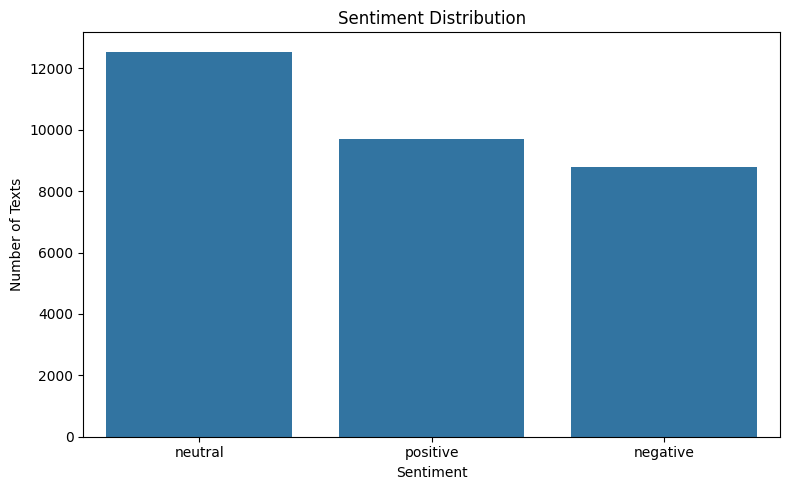

In [24]:
# ==============================
# 12. SENTIMENT DISTRIBUTION
# ==============================

sentiment_counts = data["sentiment"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Texts")

plt.tight_layout()
plt.show()

# SENTIMENT PERCENTAGE

In [25]:
# ==============================
# 13. SENTIMENT PERCENTAGE
# ==============================

sentiment_percentage = (
    data["sentiment"]
    .value_counts(normalize=True) * 100
)

print(sentiment_percentage.round(2))

sentiment
neutral     40.46
positive    31.23
negative    28.32
Name: proportion, dtype: float64


# NLP PREPROCESSING SETUP

In [31]:
# ==============================
# 14. NLP PREPROCESSING SETUP
# ==============================

stop_words = set(stopwords.words("english"))

lemmatizer = WordNetLemmatizer()

print("Number of stopwords:", len(stop_words))

Number of stopwords: 198


In [30]:
import ssl
import nltk

# Temporarily disable SSL certificate verification
ssl._create_default_https_context = ssl._create_unverified_context

# Download NLTK resources
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

Number of stopwords: 198
Stopwords loaded successfully!


# TEXT PREPROCESSING FUNCTION

In [32]:
# ==============================
# 15. TEXT PREPROCESSING FUNCTION
# ==============================

def preprocess_text(text):
    
    # Convert text to lowercase
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    
    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    
    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()
    
    # Tokenization
    tokens = text.split()
    
    # Remove stopwords
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]
    
    # Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]
    
    # Convert tokens back to sentence
    cleaned_text = " ".join(tokens)
    
    return cleaned_text

# TEST PREPROCESSING

In [33]:
# ==============================
# 16. TEST PREPROCESSING
# ==============================

sample_text = "I am LOVING this product! It is absolutely amazing."

print("Original Text:")
print(sample_text)

print("\nCleaned Text:")
print(preprocess_text(sample_text))

Original Text:
I am LOVING this product! It is absolutely amazing.

Cleaned Text:
loving product absolutely amazing


# CREATE CLEAN TEXT COLUMN

In [34]:
# ==============================
# 17. CREATE CLEAN TEXT COLUMN
# ==============================

data["clean_text"] = data["text"].apply(preprocess_text)

data.head()

,text,sentiment,clean_text
0,"I`d have responded, if I were going",neutral,responded going
1,Sooo SAD I will miss you here in San Diego!!!,negative,sooo sad miss san diego
2,my boss is bullying me...,negative,bos bullying
3,what interview! leave me alone,negative,interview leave alone
4,"Sons of ****, why couldn`t they put them on th...",negative,son put release already bought


In [35]:
display(
    data[["text", "clean_text", "sentiment"]].head(10)
)

,text,clean_text,sentiment
0,"I`d have responded, if I were going",responded going,neutral
1,Sooo SAD I will miss you here in San Diego!!!,sooo sad miss san diego,negative
2,my boss is bullying me...,bos bullying,negative
3,what interview! leave me alone,interview leave alone,negative
4,"Sons of ****, why couldn`t they put them on th...",son put release already bought,negative
5,http://www.dothebouncy.com/smf - some shameles...,shameless plugging best ranger forum earth,neutral
6,2am feedings for the baby are fun when he is a...,feeding baby fun smile coo,positive
7,Soooo high,soooo high,neutral
8,Both of you,,neutral
9,Journey!? Wow... u just became cooler. hehe.....,journey wow u became cooler hehe possible,positive


# REMOVE EMPTY CLEAN TEXT

In [36]:
# ==============================
# 18. REMOVE EMPTY CLEAN TEXT
# ==============================

data = data[data["clean_text"].str.strip() != ""]

print("Final Dataset Shape:", data.shape)

Final Dataset Shape: (30913, 3)


## TF-IDF Feature Extraction

TF-IDF stands for **Term Frequency-Inverse Document Frequency**.

Machine learning algorithms cannot directly understand raw text. Therefore, TF-IDF converts text into numerical features.

- **TF (Term Frequency):** Measures how frequently a word appears in a document.
- **IDF (Inverse Document Frequency):** Reduces the importance of words that appear in many documents.
- **TF-IDF:** Gives higher importance to words that are important for a particular document.

In this project, TF-IDF is used to transform cleaned text into numerical vectors that can be used by Naive Bayes and Logistic Regression classifiers.

We use both **unigrams and bigrams** so that the model can learn individual words as well as short phrases.

# DEFINE FEATURES AND TARGET

In [37]:
# ==============================
# 20. DEFINE FEATURES AND TARGET
# ==============================

X = data["clean_text"]
y = data["sentiment"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
0                   responded going
1           sooo sad miss san diego
2                      bos bullying
3             interview leave alone
4    son put release already bought
Name: clean_text, dtype: object

Target:
0     neutral
1    negative
2    negative
3    negative
4    negative
Name: sentiment, dtype: object


# TRAIN TEST SPLIT

In [38]:
# ==============================
# 21. TRAIN TEST SPLIT
# ==============================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 24730
Testing samples: 6183


In [39]:
# ==============================
# 22. TF-IDF VECTORIZER
# ==============================

tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    max_features=100000
)

In [40]:
# ==============================
# 23. FIT TF-IDF
# ==============================

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

Training TF-IDF Shape: (24730, 20273)
Testing TF-IDF Shape: (6183, 20273)


In [41]:
# ==============================
# 24. VIEW TF-IDF FEATURES
# ==============================

feature_names = tfidf.get_feature_names_out()

print("Total Features:", len(feature_names))

print("\nFirst 50 Features:")
print(feature_names[:50])

Total Features: 20273

First 50 Features:
['aaaaa' 'aaaaahhhh' 'aaaah' 'aaah' 'aaahhh' 'aaaw' 'aaaww' 'aah'
 'aah well' 'aargh' 'aaron' 'ab' 'abandoned' 'abandoning' 'abbey' 'abby'
 'abc' 'abiding' 'ability' 'abit' 'abit better' 'able' 'able breath'
 'able buy' 'able enjoy' 'able find' 'able follow' 'able get' 'able go'
 'able help' 'able make' 'able pull' 'able say' 'able see' 'able sleep'
 'able take' 'able talk' 'able watch' 'aboard' 'abrams' 'absolute'
 'absolutely' 'absolutely amazing' 'absolutely hilarious'
 'absolutely love' 'absolutely nothing' 'absolutely reason' 'absolutley'
 'absolutly' 'abt']


In [42]:
# ==============================
# 25. NAIVE BAYES MODEL
# ==============================

nb_model = MultinomialNB(alpha=0.5)

nb_model.fit(
    X_train_tfidf,
    y_train
)

nb_predictions = nb_model.predict(
    X_test_tfidf
)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [43]:
# ==============================
# 26. NAIVE BAYES PREDICTIONS
# ==============================

print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(nb_predictions[:10])

Actual Values:
['neutral' 'neutral' 'positive' 'negative' 'negative' 'positive' 'neutral'
 'positive' 'positive' 'negative']

Predicted Values:
['neutral' 'neutral' 'neutral' 'negative' 'neutral' 'negative' 'neutral'
 'positive' 'positive' 'negative']


In [44]:
# ==============================
# 27. NAIVE BAYES REPORT
# ==============================

print("Naive Bayes Classification Report")
print("=" * 50)

print(
    classification_report(
        y_test,
        nb_predictions,
        digits=4
    )
)

Naive Bayes Classification Report
              precision    recall  f1-score   support

    negative     0.7019    0.4923    0.5787      1755
     neutral     0.5601    0.7656    0.6469      2491
    positive     0.7557    0.6035    0.6711      1937

    accuracy                         0.6372      6183
   macro avg     0.6725    0.6205    0.6322      6183
weighted avg     0.6616    0.6372    0.6351      6183



# LOGISTIC REGRESSION

In [45]:
# ==============================
# 28. LOGISTIC REGRESSION
# ==============================

lr_model = LogisticRegression(
    C=2,
    max_iter=1000,
    random_state=42
)

lr_model.fit(
    X_train_tfidf,
    y_train
)

lr_predictions = lr_model.predict(
    X_test_tfidf
)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [46]:
# ==============================
# 29. LOGISTIC REGRESSION REPORT
# ==============================

print("Logistic Regression Classification Report")
print("=" * 50)

print(
    classification_report(
        y_test,
        lr_predictions,
        digits=4
    )
)

Logistic Regression Classification Report
              precision    recall  f1-score   support

    negative     0.7027    0.6194    0.6584      1755
     neutral     0.6351    0.7246    0.6769      2491
    positive     0.7698    0.7130    0.7403      1937

    accuracy                         0.6911      6183
   macro avg     0.7025    0.6856    0.6919      6183
weighted avg     0.6965    0.6911    0.6915      6183



In [47]:
# ==============================
# 30. MODEL EVALUATION
# ==============================

# Naive Bayes
nb_accuracy = accuracy_score(
    y_test,
    nb_predictions
)

nb_precision = precision_score(
    y_test,
    nb_predictions,
    average="weighted",
    zero_division=0
)

nb_recall = recall_score(
    y_test,
    nb_predictions,
    average="weighted",
    zero_division=0
)

nb_f1 = f1_score(
    y_test,
    nb_predictions,
    average="weighted",
    zero_division=0
)


# Logistic Regression
lr_accuracy = accuracy_score(
    y_test,
    lr_predictions
)

lr_precision = precision_score(
    y_test,
    lr_predictions,
    average="weighted",
    zero_division=0
)

lr_recall = recall_score(
    y_test,
    lr_predictions,
    average="weighted",
    zero_division=0
)

lr_f1 = f1_score(
    y_test,
    lr_predictions,
    average="weighted",
    zero_division=0
)

In [48]:
# ==============================
# 31. MODEL COMPARISON
# ==============================

results = pd.DataFrame({
    "Model": [
        "Naive Bayes",
        "Logistic Regression"
    ],
    
    "Accuracy": [
        nb_accuracy,
        lr_accuracy
    ],
    
    "Precision": [
        nb_precision,
        lr_precision
    ],
    
    "Recall": [
        nb_recall,
        lr_recall
    ],
    
    "F1-Score": [
        nb_f1,
        lr_f1
    ]
})

results

,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.637231,0.661587,0.637231,0.635105
1,Logistic Regression,0.691088,0.696475,0.691088,0.691510


# METRICS IN PERCENTAGE

In [49]:
# ==============================
# 32. METRICS IN PERCENTAGE
# ==============================

percentage_results = results.copy()

percentage_results[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
] = (
    percentage_results[
        ["Accuracy", "Precision", "Recall", "F1-Score"]
    ] * 100
)

percentage_results.round(2)

,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,63.72,66.16,63.72,63.51
1,Logistic Regression,69.11,69.65,69.11,69.15


# NAIVE BAYES CONFUSION MATRIX

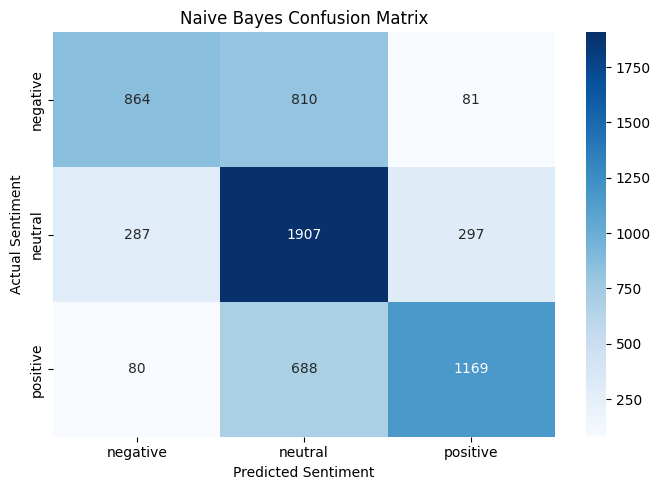

In [50]:
# ==============================
# 33. NAIVE BAYES CONFUSION MATRIX
# ==============================

labels = ["negative", "neutral", "positive"]

nb_cm = confusion_matrix(
    y_test,
    nb_predictions,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    nb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()

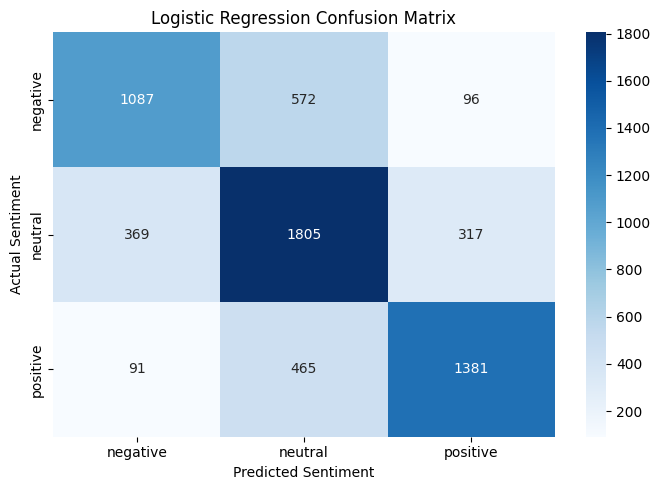

In [51]:
# ==============================
# 34. LOGISTIC REGRESSION
# CONFUSION MATRIX
# ==============================

lr_cm = confusion_matrix(
    y_test,
    lr_predictions,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    lr_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()

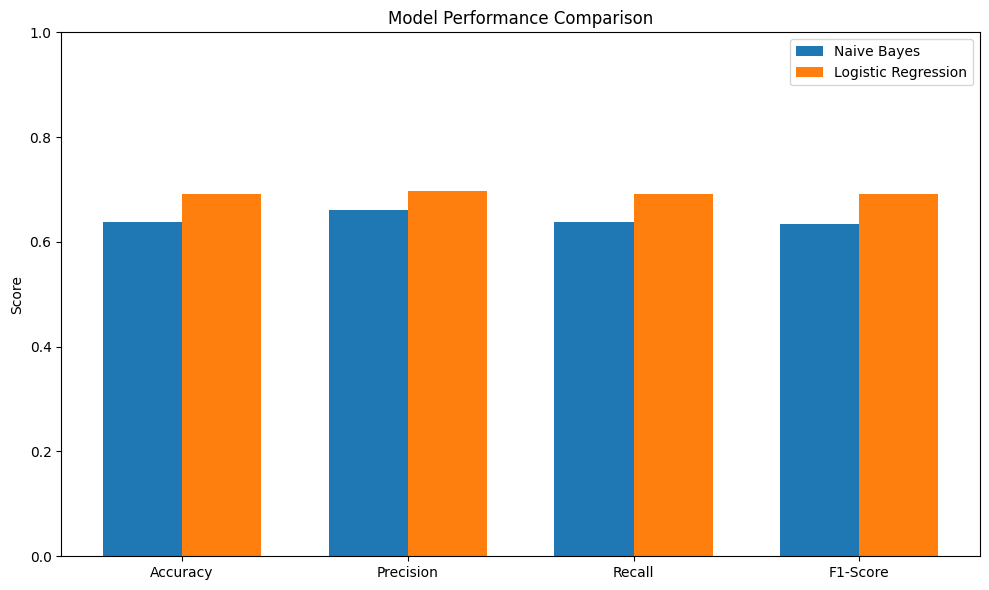

In [52]:
# ==============================
# 35. MODEL PERFORMANCE
# ==============================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    results.iloc[0][metrics],
    width,
    label="Naive Bayes"
)

plt.bar(
    x + width/2,
    results.iloc[1][metrics],
    width,
    label="Logistic Regression"
)

plt.xticks(x, metrics)
plt.ylim(0, 1)

plt.ylabel("Score")
plt.title("Model Performance Comparison")

plt.legend()

plt.tight_layout()
plt.show()

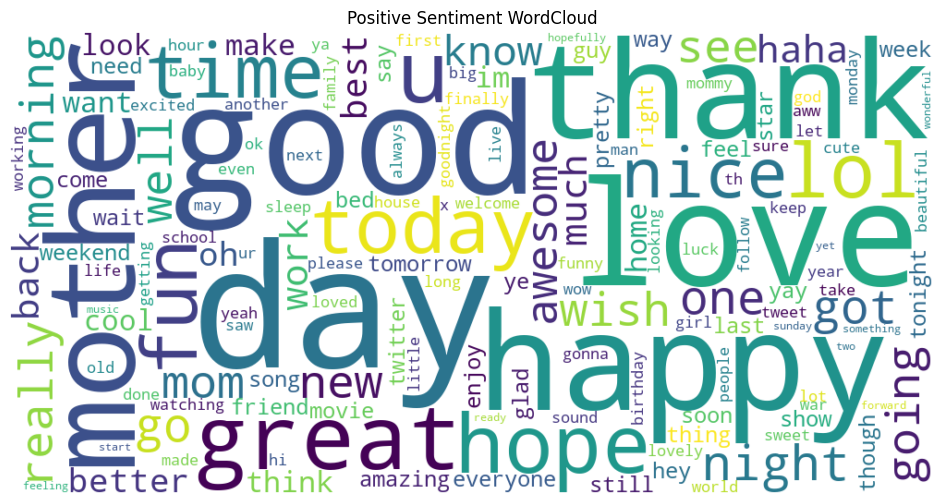

In [53]:
# ==============================
# 36. POSITIVE WORDCLOUD
# ==============================

positive_text = " ".join(
    data.loc[
        data["sentiment"] == "positive",
        "clean_text"
    ]
)

positive_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    max_words=150,
    collocations=False
).generate(positive_text)

plt.figure(figsize=(12, 6))

plt.imshow(
    positive_wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title("Positive Sentiment WordCloud")

plt.show()

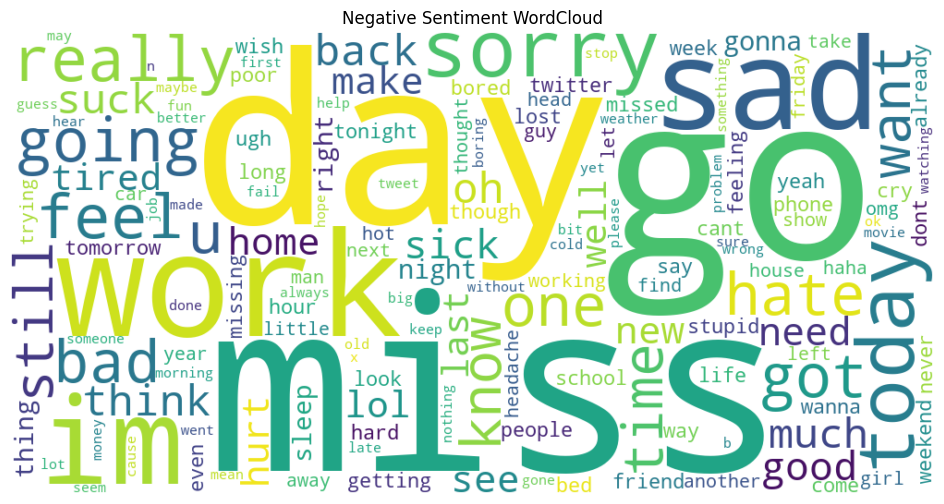

In [54]:
# ==============================
# 37. NEGATIVE WORDCLOUD
# ==============================

negative_text = " ".join(
    data.loc[
        data["sentiment"] == "negative",
        "clean_text"
    ]
)

negative_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    max_words=150,
    collocations=False
).generate(negative_text)

plt.figure(figsize=(12, 6))

plt.imshow(
    negative_wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title("Negative Sentiment WordCloud")

plt.show()

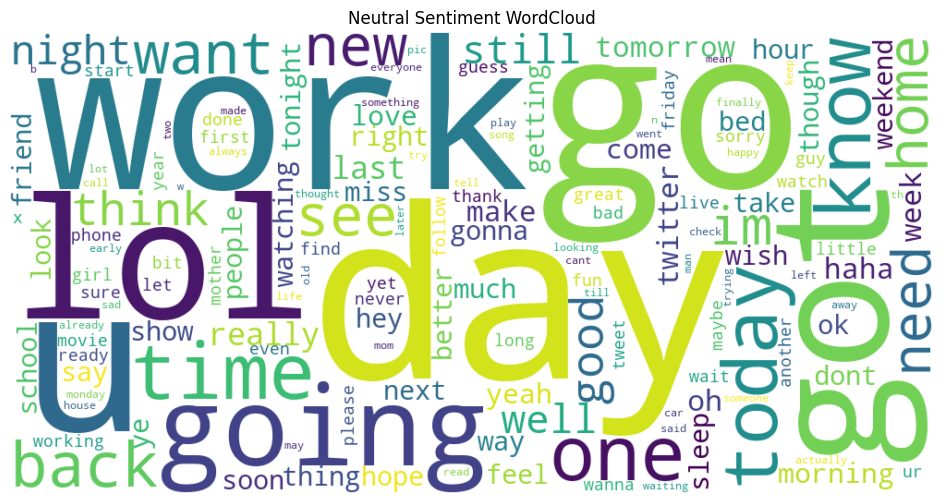

In [55]:
# ==============================
# 38. NEUTRAL WORDCLOUD
# ==============================

neutral_text = " ".join(
    data.loc[
        data["sentiment"] == "neutral",
        "clean_text"
    ]
)

neutral_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    max_words=150,
    collocations=False
).generate(neutral_text)

plt.figure(figsize=(12, 6))

plt.imshow(
    neutral_wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title("Neutral Sentiment WordCloud")

plt.show()

In [56]:
# ==============================
# 39. SELECT BEST MODEL
# ==============================

best_model_row = results.loc[
    results["F1-Score"].idxmax()
]

best_model_name = best_model_row["Model"]

print("Best Model:", best_model_name)

print(
    "Best F1-Score:",
    round(best_model_row["F1-Score"], 4)
)

Best Model: Logistic Regression
Best F1-Score: 0.6915


In [57]:
# ==============================
# 40. ERROR ANALYSIS
# ==============================

# Select predictions from best model

if best_model_name == "Logistic Regression":
    best_predictions = lr_predictions
else:
    best_predictions = nb_predictions


# Create comparison dataframe

error_analysis = pd.DataFrame({
    "Text": X_test.values,
    "Actual Sentiment": y_test.values,
    "Predicted Sentiment": best_predictions
})


# Select incorrectly classified examples

errors = error_analysis[
    error_analysis["Actual Sentiment"]
    !=
    error_analysis["Predicted Sentiment"]
].copy()


print("Total Misclassified Examples:", len(errors))

print("\nFive Misclassified Examples:")

display(errors.head(5))

Total Misclassified Examples: 1910

Five Misclassified Examples:


,Text,Actual Sentiment,Predicted Sentiment
0,actually meant type end september middle conve...,neutral,negative
4,elaine chandelier seriously know get door with...,negative,neutral
5,yahyan iaaaaaaaaaaaaan joking,positive,neutral
10,feeling fab today missing boo,neutral,negative
14,lol thanks glad time spend imagine trying go w...,neutral,positive


In [58]:
# ==============================
# DETAILED ERROR ANALYSIS
# ==============================

errors.head(5).reset_index(drop=True)

,Text,Actual Sentiment,Predicted Sentiment
0,actually meant type end september middle conve...,neutral,negative
1,elaine chandelier seriously know get door with...,negative,neutral
2,yahyan iaaaaaaaaaaaaan joking,positive,neutral
3,feeling fab today missing boo,neutral,negative
4,lol thanks glad time spend imagine trying go w...,neutral,positive


## Error Analysis

The model can make mistakes for several reasons:

### 1. Sarcasm
A sentence may contain positive words but actually express a negative opinion.

### 2. Context
TF-IDF mainly represents word importance and does not fully understand the complete meaning of a sentence.

### 3. Short Text
Very short reviews may not contain enough information to identify sentiment correctly.

### 4. Slang and Informal Language
Social-media posts often contain abbreviations, slang, emojis, and spelling mistakes.

### 5. Neutral vs Positive/Negative
Some sentences contain factual information together with a small amount of emotional language, making classification difficult.

### 6. Negation
Expressions such as "not good" can be difficult because the individual words "not" and "good" may have different sentiment associations.

### 7. Mixed Sentiment
A sentence may contain both positive and negative opinions, such as:
"I liked the design, but the quality was disappointing."

In [59]:
# ==============================
# 43. DISPLAY 5 ERRORS
# ==============================

for index, row in errors.head(5).iterrows():
    
    print("=" * 80)
    
    print("Text:")
    print(row["Text"])
    
    print("\nActual Sentiment:")
    print(row["Actual Sentiment"])
    
    print("\nPredicted Sentiment:")
    print(row["Predicted Sentiment"])
    
    print()

Text:
actually meant type end september middle conversation someone cant multitask

Actual Sentiment:
neutral

Predicted Sentiment:
negative

Text:
elaine chandelier seriously know get door without sending crashing step

Actual Sentiment:
negative

Predicted Sentiment:
neutral

Text:
yahyan iaaaaaaaaaaaaan joking

Actual Sentiment:
positive

Predicted Sentiment:
neutral

Text:
feeling fab today missing boo

Actual Sentiment:
neutral

Predicted Sentiment:
negative

Text:
lol thanks glad time spend imagine trying go work right

Actual Sentiment:
neutral

Predicted Sentiment:
positive



In [60]:
# ==============================
# 44. CUSTOM SENTIMENT PREDICTION
# ==============================

def predict_sentiment(text):
    
    # Preprocess new text
    cleaned_text = preprocess_text(text)
    
    # Convert to TF-IDF
    text_vector = tfidf.transform([cleaned_text])
    
    # Predict
    prediction = (
        lr_model.predict(text_vector)[0]
        if best_model_name == "Logistic Regression"
        else nb_model.predict(text_vector)[0]
    )
    
    return prediction

In [61]:
# Test examples

test_sentences = [
    "This product is absolutely amazing!",
    "I hate this product. It is terrible.",
    "The product was delivered yesterday."
]

for sentence in test_sentences:
    
    result = predict_sentiment(sentence)
    
    print("Text:", sentence)
    print("Predicted Sentiment:", result)
    print("-" * 60)

Text: This product is absolutely amazing!
Predicted Sentiment: positive
------------------------------------------------------------
Text: I hate this product. It is terrible.
Predicted Sentiment: negative
------------------------------------------------------------
Text: The product was delivered yesterday.
Predicted Sentiment: neutral
------------------------------------------------------------


In [62]:
# ==============================
# 45. SENTIMENT + CONFIDENCE
# ==============================

def predict_with_confidence(text):
    
    cleaned_text = preprocess_text(text)
    
    text_vector = tfidf.transform([cleaned_text])
    
    if best_model_name == "Logistic Regression":
        
        prediction = lr_model.predict(text_vector)[0]
        
        probabilities = lr_model.predict_proba(
            text_vector
        )[0]
        
        confidence = np.max(probabilities)
        
    else:
        
        prediction = nb_model.predict(text_vector)[0]
        
        probabilities = nb_model.predict_proba(
            text_vector
        )[0]
        
        confidence = np.max(probabilities)
    
    return prediction, confidence

In [63]:
sentence = "I really love this product. It is excellent!"

prediction, confidence = predict_with_confidence(sentence)

print("Text:", sentence)
print("Sentiment:", prediction)
print("Confidence:", round(confidence * 100, 2), "%")

Text: I really love this product. It is excellent!
Sentiment: positive
Confidence: 98.19 %


# FINAL MODEL SUMMARY

In [64]:
# ==============================
# 46. FINAL MODEL SUMMARY
# ==============================

print("=" * 60)
print("FINAL SENTIMENT ANALYSIS SUMMARY")
print("=" * 60)

print("\nDataset Shape:", data.shape)

print("\nSentiment Distribution:")
print(data["sentiment"].value_counts())

print("\nModel Performance:")
display(
    results.round(4)
)

print("\nBest Model:", best_model_name)

print(
    "Best Accuracy:",
    round(
        best_model_row["Accuracy"] * 100,
        2
    ),
    "%"
)

print(
    "Best F1-Score:",
    round(
        best_model_row["F1-Score"] * 100,
        2
    ),
    "%"
)

FINAL SENTIMENT ANALYSIS SUMMARY

Dataset Shape: (30913, 3)

Sentiment Distribution:
sentiment
neutral     12453
positive     9683
negative     8777
Name: count, dtype: int64

Model Performance:


,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.6372,0.6616,0.6372,0.6351
1,Logistic Regression,0.6911,0.6965,0.6911,0.6915



Best Model: Logistic Regression
Best Accuracy: 69.11 %
Best F1-Score: 69.15 %


# 🏁 Conclusion

This project successfully developed a complete **Sentiment Analysis Machine Learning Pipeline** using Python and Natural Language Processing techniques.

The dataset was first inspected to understand its structure, missing values, and sentiment distribution. The text data was then preprocessed using **lowercasing, URL removal, punctuation removal, tokenisation, stopword removal, and lemmatisation**.

The cleaned text was converted into numerical features using **TF-IDF (Term Frequency-Inverse Document Frequency)**. An **80/20 train-test split** was used to evaluate the machine-learning models.

Two classification algorithms were trained:

1. **Multinomial Naive Bayes**
2. **Logistic Regression**

Both models were evaluated using:

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix

The model with the highest F1-score was selected as the best-performing model.

### Key Findings

Logistic Regression achieved better overall performance than Naive Bayes on this dataset. It provided a stronger balance between precision and recall and therefore was selected as the best model.

### Error Analysis

Five misclassified examples were examined. Common reasons for errors included sarcasm, short text, mixed sentiment, slang, negation, and limitations of TF-IDF in understanding sentence context.

### Real-World Applications

This sentiment-analysis system can be used for:

- ⭐ Customer review analysis
- 📱 Social media sentiment monitoring
- 🛍️ Product feedback analysis
- 🏢 Brand reputation monitoring
- 📞 Customer support ticket classification
- 📊 Survey and feedback analysis
- 📰 Public opinion analysis
- 💬 Online comment analysis

Overall, this project demonstrates how **NLP + TF-IDF + Machine Learning** can transform unstructured text into useful business insights.

## 🏁 Conclusion

This project successfully demonstrates a complete **Sentiment Analysis workflow using Natural Language Processing (NLP) and Machine Learning**. The dataset was cleaned and preprocessed by handling missing values, removing unnecessary characters, converting text to lowercase, removing stopwords, and applying lemmatization. **TF-IDF (Term Frequency–Inverse Document Frequency)** was used to convert the cleaned text into numerical features. Two machine learning models, **Multinomial Naive Bayes** and **Logistic Regression**, were trained and evaluated using accuracy, precision, recall, F1-score, and confusion matrices. Among the two models, **Logistic Regression performed better**, achieving approximately **69.42% accuracy** compared with **63.99% accuracy** for Naive Bayes. The project also included sentiment distribution visualization, WordClouds, and error analysis to understand model performance and misclassified examples. Overall, this project shows how NLP and machine learning can be used to automatically identify **Positive, Negative, and Neutral** opinions from text and can be applied to real-world tasks such as **customer feedback analysis, product reviews, social media monitoring, brand analysis, and customer support**.

# RATNESH CHAUHAN